# 01 – Eksploracyjna analiza danych (GTSRB)

Cel: poznać zbiór przed treningiem – liczności i nierównowagę klas, rozmiary zdjęć, strukturę serii (tracków),
jasność zdjęć – oraz obejrzeć augmentacje A1 i A2.

- Wykresy zapisują się do `results/eda/`, kluczowe liczby do `results/eda/summary.json`.
- Podział train/val jest wczytywany z `splits/val_tracks.json` (tworzy go `python -m src.data`).
- **Zbiór testowy:** w EDA używamy tylko metadanych z `Test.csv` (etykiety, rozmiary). Zdjęć testowych nie oglądamy –
  test jest zarezerwowany do jednorazowej oceny w KM3.

In [1]:
import json
import sys
import textwrap
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image, ImageStat

from src.data import (CLASS_NAMES, DATA_DIR, IMG_SIZE, NUM_CLASSES, SEED, GTSRBDataset, build_transform,
                      denormalize, get_train_val, load_csv, seed_everything, split_stats)

OUT = ROOT / "results" / "eda"
OUT.mkdir(parents=True, exist_ok=True)
seed_everything(SEED)

# Chart style: light surface, recessive grid and axes, text in ink colors (not series colors).
COLORS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "Segoe UI", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False, "savefig.dpi": 150, "savefig.bbox": "tight",
})

A0 = build_transform("A0")


def load_rgb(path):
    with Image.open(DATA_DIR / path) as im:
        return im.convert("RGB")


def to_display(x):
    # normalized [3, H, W] tensor -> [H, W, 3] array in [0, 1]
    return denormalize(x).permute(1, 2, 0).numpy()


def show(ax, img, title=None, fontsize=8):
    ax.imshow(img)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=fontsize, color=INK2)


def save(fig, name):
    fig.savefig(OUT / name)
    plt.show()

## 1. Dane i podział train/val

Walidacja to ok. 20% **serii** z `Train/` (StratifiedGroupKFold, grupy = id serii `<klasa>_<seria>`, seed 42).
Podział po seriach, a nie po zdjęciach, jest konieczny: ok. 30 klatek jednej serii to niemal identyczne zdjęcia
tego samego znaku, więc losowy podział zdjęć dałby przeciek i zawyżoną accuracy walidacyjną.

In [2]:
full = load_csv("train")          # whole Train/ folder (train + val)
train_df, val_df = get_train_val()
test_df = load_csv("test")
split = split_stats(train_df, val_df)

frames = full.groupby("track").size()
print(f"Train/: {len(full)} zdjęć, {full.track.nunique()} serii, {NUM_CLASSES} klas; "
      f"klatek na serię: min {frames.min()}, mediana {int(frames.median())}, max {frames.max()}")
print(f"Test/:  {len(test_df)} zdjęć")
print(f"train:  {split['n_images']['train']} zdjęć, {split['n_tracks']['train']} serii")
print(f"val:    {split['n_images']['val']} zdjęć, {split['n_tracks']['val']} serii "
      f"({split['val_fraction_tracks']:.1%} serii, {split['val_fraction_images']:.1%} zdjęć)")
print(f"wspólne serie train/val: {split['shared_tracks']}")
print(f"klasy w val: {split['val_classes']}/{NUM_CLASSES}; min. serii na klasę w val: {split['val_min_tracks_per_class']}; "
      f"min. zdjęć na klasę w val: {split['val_min_images_per_class']} (klasa {split['val_min_images_class']})")

Train/: 39209 zdjęć, 1307 serii, 43 klas; klatek na serię: min 29, mediana 30, max 30
Test/:  12630 zdjęć
train:  31349 zdjęć, 1045 serii
val:    7860 zdjęć, 262 serii (20.1% serii, 20.1% zdjęć)
wspólne serie train/val: 0
klasy w val: 43/43; min. serii na klasę w val: 1; min. zdjęć na klasę w val: 30 (klasa 0)


## 2. Rozkład klas

Górny wykres: liczby zdjęć, dolny: udział klasy w danym zbiorze (porównanie kształtu rozkładów).
Pełna tabela jest niżej i w `results/eda/class_counts.csv`.

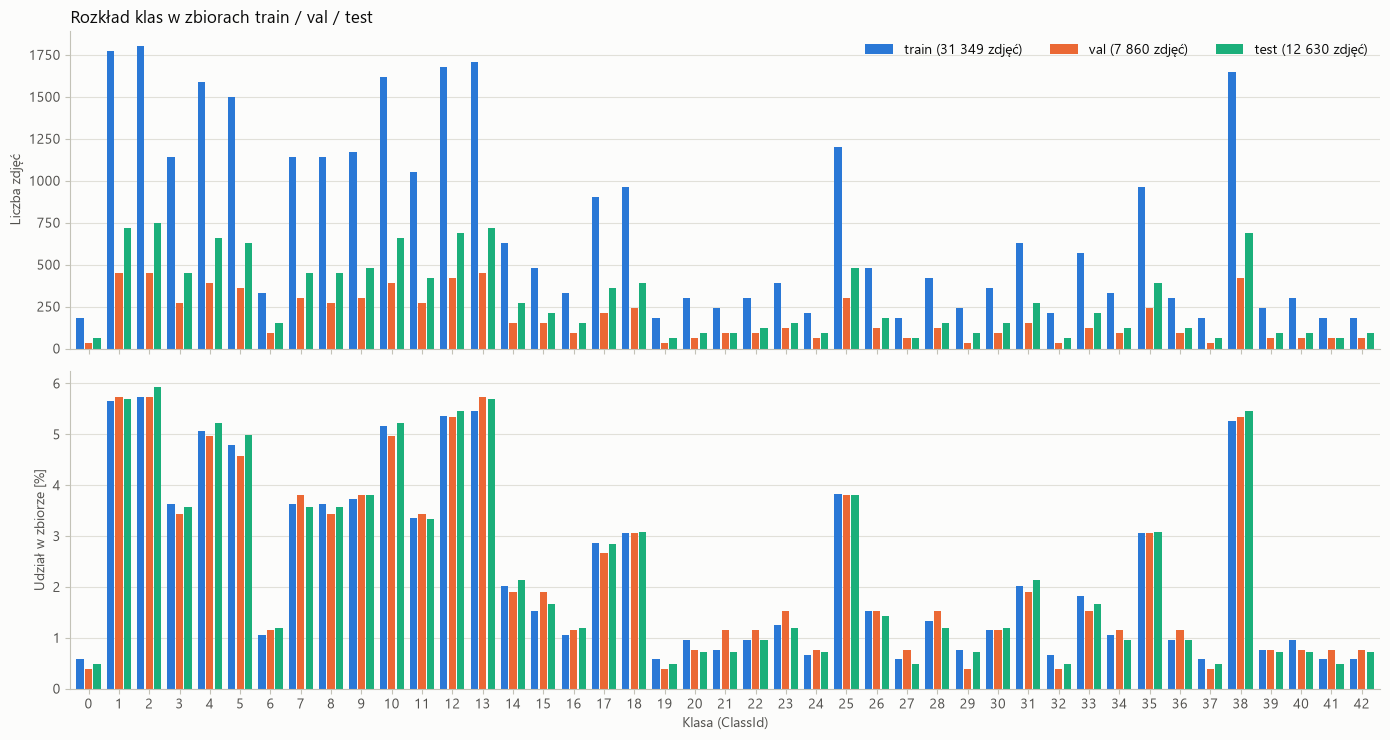

Train/: najmniej zdjęć klasa 0 (210), najwięcej klasa 2 (2250), stosunek 10.7x
Największa różnica udziału klasy train vs val: 0.38 p.p.


,name,train,val,test,train_tracks,val_tracks
ClassId,,,,,,
0,Speed limit (20km/h),180,30,60,6,1
1,Speed limit (30km/h),1770,450,720,59,15
2,Speed limit (50km/h),1800,450,750,60,15
3,Speed limit (60km/h),1140,270,450,38,9
4,Speed limit (70km/h),1590,390,660,53,13
5,Speed limit (80km/h),1500,360,630,50,12
6,End of speed limit (80km/h),330,90,150,11,3
7,Speed limit (100km/h),1140,300,450,38,10
8,Speed limit (120km/h),1140,270,450,38,9


In [3]:
SPLITS = ["train", "val", "test"]
counts = pd.DataFrame({
    "train": train_df.ClassId.value_counts(),
    "val": val_df.ClassId.value_counts(),
    "test": test_df.ClassId.value_counts(),
}).reindex(range(NUM_CLASSES)).fillna(0).astype(int)
counts.index.name = "ClassId"
counts.insert(0, "name", CLASS_NAMES)
counts["train_tracks"] = train_df.groupby("ClassId").track.nunique()
counts["val_tracks"] = val_df.groupby("ClassId").track.nunique()
counts.to_csv(OUT / "class_counts.csv")
share = counts[SPLITS] / counts[SPLITS].sum() * 100

x = np.arange(NUM_CLASSES)
w = 0.28
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True)
for ax, data, ylabel in [(axes[0], counts, "Liczba zdjęć"), (axes[1], share, "Udział w zbiorze [%]")]:
    for k, s in enumerate(SPLITS):
        ax.bar(x + (k - 1) * w, data[s], width=w * 0.85, color=COLORS[s],
               label=f"{s} ({counts[s].sum():,} zdjęć)".replace(",", " "))
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
axes[0].set_title("Rozkład klas w zbiorach train / val / test", loc="left")
axes[0].legend(loc="upper right", ncols=3)
axes[1].set_xticks(x, [str(i) for i in x])
axes[1].set_xlabel("Klasa (ClassId)")
axes[1].set_xlim(-0.6, NUM_CLASSES - 0.4)
fig.tight_layout()
save(fig, "class_distribution.png")

per_class = full.ClassId.value_counts()
print(f"Train/: najmniej zdjęć klasa {per_class.idxmin()} ({per_class.min()}), najwięcej klasa {per_class.idxmax()} "
      f"({per_class.max()}), stosunek {per_class.max() / per_class.min():.1f}x")
max_share_diff = (share["train"] - share["val"]).abs().max()
print(f"Największa różnica udziału klasy train vs val: {max_share_diff:.2f} p.p.")
counts

## 3. Rozmiary zdjęć

Wszystkie zdjęcia są skalowane do 64×64 px. Linia pionowa oznacza rozmiar wejścia sieci.

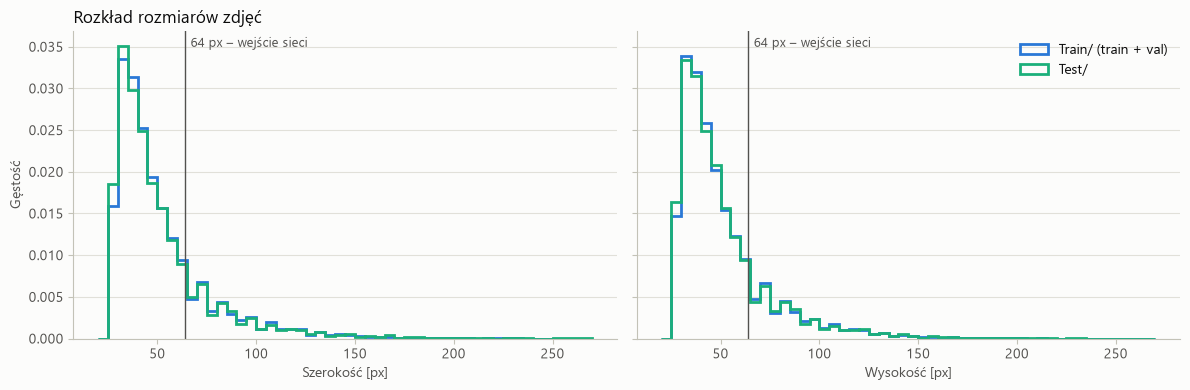

train_folder: szer. {'min': 25, 'median': 43.0, 'max': 243}, wys. {'min': 25, 'median': 43.0, 'max': 225}
   oba boki < 64 px (powiększane): 79.3%; proporcje W/H (p1, mediana, p99): [0.811, 1.0, 1.174]
test: szer. {'min': 25, 'median': 43.0, 'max': 266}, wys. {'min': 25, 'median': 43.0, 'max': 232}
   oba boki < 64 px (powiększane): 79.5%; proporcje W/H (p1, mediana, p99): [0.643, 1.0, 1.172]


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = np.arange(20, 275, 5)
for ax, col, label in [(axes[0], "Width", "Szerokość [px]"), (axes[1], "Height", "Wysokość [px]")]:
    for s, df, name in [("train", full, "Train/ (train + val)"), ("test", test_df, "Test/")]:
        ax.hist(df[col], bins=bins, density=True, histtype="step", linewidth=2, color=COLORS[s], label=name)
    ax.axvline(IMG_SIZE, color=INK2, linewidth=1)
    ax.annotate("64 px – wejście sieci", (IMG_SIZE, 1), xycoords=("data", "axes fraction"),
                xytext=(4, -4), textcoords="offset points", va="top", fontsize=9, color=INK2)
    ax.set_xlabel(label)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Gęstość")
axes[0].set_title("Rozkład rozmiarów zdjęć", loc="left")
axes[1].legend(loc="upper right")
fig.tight_layout()
save(fig, "image_sizes.png")


def size_stats(df):
    side = df[["Width", "Height"]].max(axis=1)
    aspect = df.Width / df.Height
    return {
        "width": {"min": int(df.Width.min()), "median": float(df.Width.median()), "max": int(df.Width.max())},
        "height": {"min": int(df.Height.min()), "median": float(df.Height.median()), "max": int(df.Height.max())},
        "share_both_sides_below_64": round(float((side < IMG_SIZE).mean()), 4),
        "aspect_w_h": {"p1": round(float(aspect.quantile(0.01)), 3), "median": round(float(aspect.median()), 3),
                       "p99": round(float(aspect.quantile(0.99)), 3)},
    }


sizes = {"train_folder": size_stats(full), "test": size_stats(test_df)}
for k, v in sizes.items():
    print(f"{k}: szer. {v['width']}, wys. {v['height']}")
    print(f"   oba boki < 64 px (powiększane): {v['share_both_sides_below_64']:.1%}; "
          f"proporcje W/H (p1, mediana, p99): {list(v['aspect_w_h'].values())}")

## 4. Przykład z każdej klasy

Ostatnia klatka losowej serii (najbliżej kamery), w rozdzielczości 64×64, czyli tak, jak widzi ją sieć.

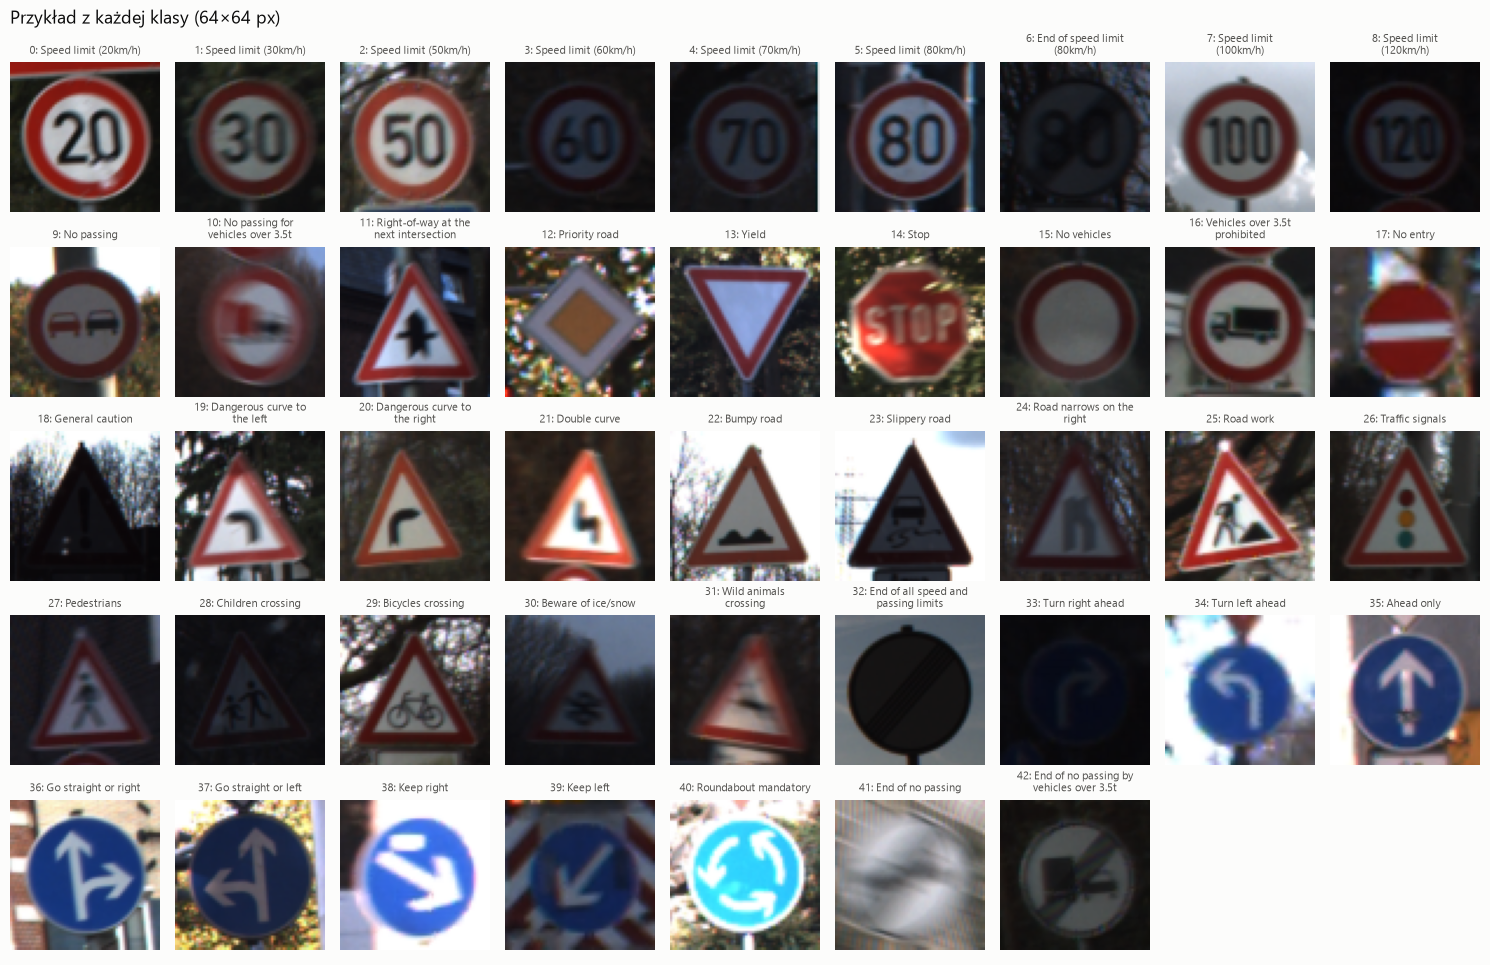

In [5]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(5, 9, figsize=(15, 9.8))
for ax in axes.flat:
    ax.axis("off")
for cls, ax in zip(range(NUM_CLASSES), axes.flat):
    tracks = sorted(full.loc[full.ClassId == cls, "track"].unique())
    track = tracks[rng.integers(len(tracks))]
    row = full[full.track == track].sort_values("frame").iloc[-1]
    show(ax, to_display(A0(load_rgb(row.Path))), f"{cls}: " + textwrap.fill(CLASS_NAMES[cls], 20))
fig.suptitle("Przykład z każdej klasy (64×64 px)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save(fig, "class_examples.png")

## 5. Jedna seria (track)

Co 5. klatka jednej serii. Górny rząd: oryginalna rozdzielczość we wspólnej skali (znak rośnie, bo samochód się zbliża),
z ramką ROI z CSV. Dolny rząd: te same klatki po przeskalowaniu do 64×64 z ramką ROI zwracaną przez `GTSRBDataset`
(kontrola przeskalowania ROI).

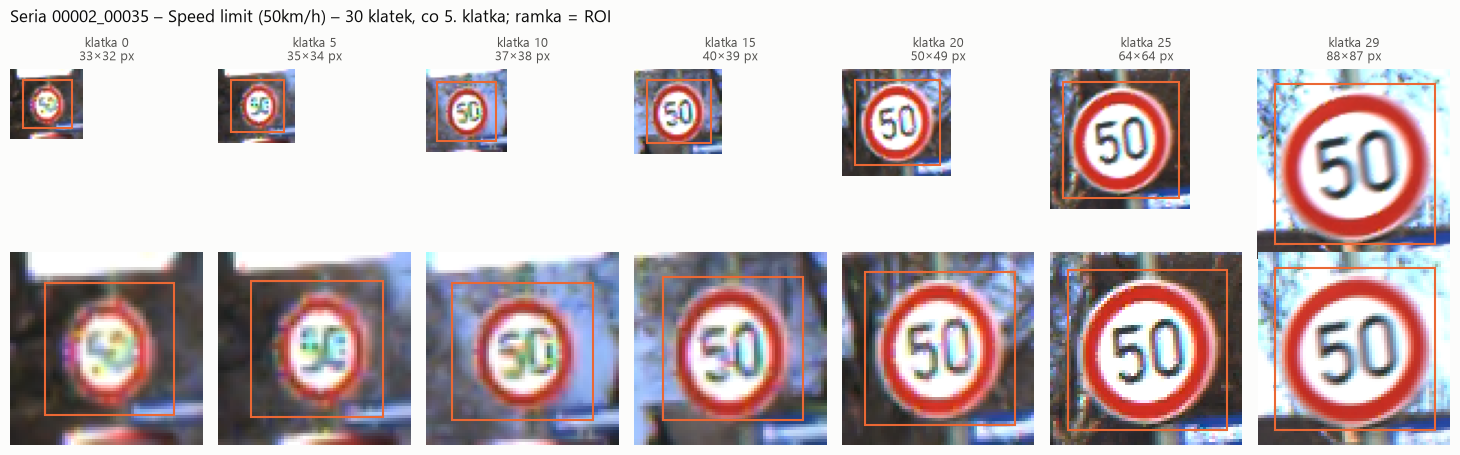

Seria 00002_00035: rozmiar od 32×32 do 88×87 px


In [6]:
track = sorted(full.track.unique())[np.random.default_rng(SEED).integers(full.track.nunique())]
seq = full[full.track == track].sort_values("frame")
picked = seq[seq.frame % 5 == 0]
if seq.frame.iloc[-1] % 5:
    picked = pd.concat([picked, seq.iloc[[-1]]])
ds = GTSRBDataset(picked)
max_w, max_h = picked.Width.max(), picked.Height.max()

fig, axes = plt.subplots(2, len(picked), figsize=(2.1 * len(picked), 4.6))
for j, (i, row) in enumerate(picked.reset_index(drop=True).iterrows()):
    ax = axes[0, j]
    ax.imshow(load_rgb(row.Path), extent=(0, row.Width, row.Height, 0))
    ax.add_patch(Rectangle((row["Roi.X1"], row["Roi.Y1"]), row["Roi.X2"] - row["Roi.X1"], row["Roi.Y2"] - row["Roi.Y1"],
                           fill=False, edgecolor="#eb6834", linewidth=1.5))
    ax.set_xlim(0, max_w)
    ax.set_ylim(max_h, 0)
    ax.axis("off")
    ax.set_title(f"klatka {row.frame}\n{row.Width}×{row.Height} px", fontsize=9, color=INK2)
    img_t, _, roi = ds[j]
    show(axes[1, j], to_display(img_t))
    x1, y1, x2, y2 = roi.tolist()
    axes[1, j].add_patch(Rectangle((x1 - 0.5, y1 - 0.5), x2 - x1, y2 - y1, fill=False, edgecolor="#eb6834", linewidth=1.5))
name = CLASS_NAMES[int(seq.ClassId.iloc[0])]
fig.suptitle(f"Seria {track} – {name} – {len(seq)} klatek, co 5. klatka; ramka = ROI", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "track_example.png")
print(f"Seria {track}: rozmiar od {seq.Width.min()}×{seq.Height.min()} do {seq.Width.max()}×{seq.Height.max()} px")

## 6. Jasność zdjęć i najciemniejsze przykłady

Jasność = średnia luminancja zdjęcia (skala 0–255), liczona dla wszystkich zdjęć z `Train/`.
Najciemniejsze przykłady pokazujemy po jednym z serii (najciemniejsza klatka), żeby nie oglądać wielu klatek tego samego znaku.
Pod każdym zdjęciem ten sam obraz z rozciągniętym kontrastem (percentyle 1–99) – tylko do podglądu, sieć widzi oryginał.

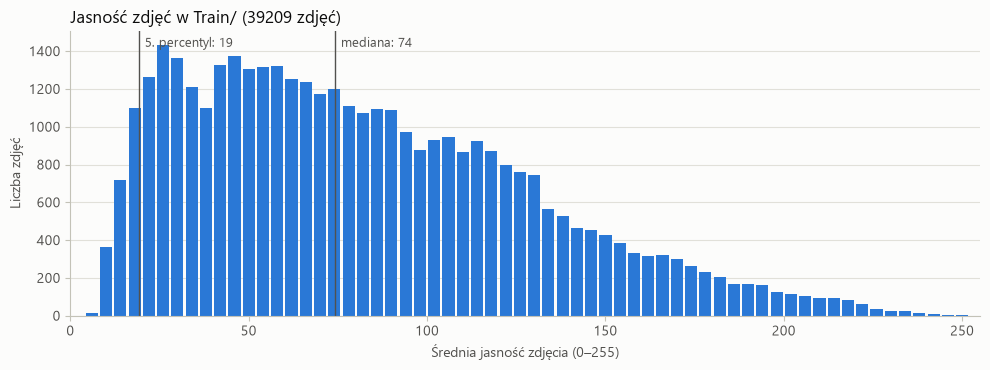

percentyle jasności: {0.01: 12.1, 0.05: 19.3, 0.5: 74.3, 0.95: 172.4}
zdjęcia z jasnością < 20: 5.6%
zdjęcia z jasnością < 30: 14.3%
zdjęcia z jasnością < 50: 30.3%


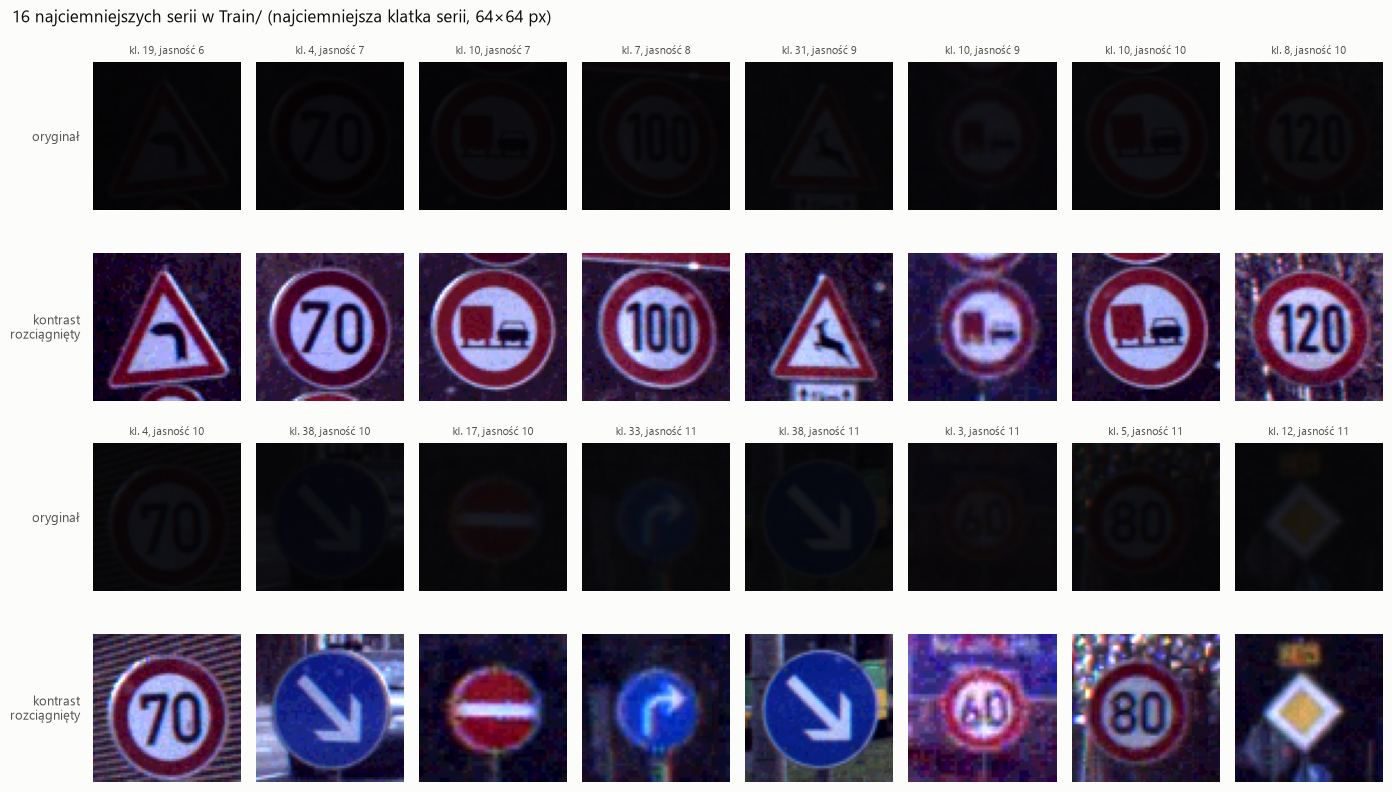

klasy wśród 16 najciemniejszych serii: {10: 3, 4: 2, 38: 2, 19: 1, 7: 1, 31: 1, 8: 1, 17: 1, 33: 1, 3: 1, 5: 1, 12: 1}


In [7]:
def mean_brightness(path):
    with Image.open(DATA_DIR / path) as im:
        return ImageStat.Stat(im.convert("L")).mean[0]


with ThreadPoolExecutor(max_workers=8) as pool:
    full["brightness"] = list(pool.map(mean_brightness, full.Path))
b = full.brightness
q = b.quantile([0.01, 0.05, 0.5, 0.95]).round(1)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(b, bins=np.arange(0, 256, 4), color=COLORS["train"], rwidth=0.85)
for p, label in [(0.05, "5. percentyl"), (0.5, "mediana")]:
    ax.axvline(q[p], color=INK2, linewidth=1)
    ax.annotate(f"{label}: {q[p]:.0f}", (q[p], 1), xycoords=("data", "axes fraction"), xytext=(4, -4),
                textcoords="offset points", va="top", fontsize=9, color=INK2)
ax.set_xlabel("Średnia jasność zdjęcia (0–255)")
ax.set_ylabel("Liczba zdjęć")
ax.set_title(f"Jasność zdjęć w Train/ ({len(full)} zdjęć)", loc="left")
ax.grid(axis="x", visible=False)
ax.set_xlim(0, 255)
fig.tight_layout()
save(fig, "brightness_hist.png")
print("percentyle jasności:", q.to_dict())
for t in (20, 30, 50):
    print(f"zdjęcia z jasnością < {t}: {(b < t).mean():.1%}")

darkest = full.loc[full.groupby("track").brightness.idxmin()].nsmallest(16, "brightness")
fig, axes = plt.subplots(4, 8, figsize=(14, 8.2))
for k, (_, row) in enumerate(darkest.iterrows()):
    r, c = 2 * (k // 8), k % 8
    img = to_display(A0(load_rgb(row.Path)))
    lo, hi = np.percentile(img, [1, 99])
    show(axes[r, c], img, f"kl. {row.ClassId}, jasność {row.brightness:.0f}")
    show(axes[r + 1, c], np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1))
for r in range(4):
    label = "oryginał" if r % 2 == 0 else "kontrast\nrozciągnięty"
    axes[r, 0].text(-6, 32, label, ha="right", va="center", fontsize=9, color=INK2)
fig.suptitle("16 najciemniejszych serii w Train/ (najciemniejsza klatka serii, 64×64 px)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "darkest_examples.png")
print("klasy wśród 16 najciemniejszych serii:", darkest.ClassId.value_counts().to_dict())

## 7. Augmentacje A1 i A2

- **A0** – tylko resize 64×64 i normalizacja ImageNet (też walidacja i test).
- **A1** – geometryczna: obrót ±10°, przesunięcie ±10%, skala 0.9–1.1 (RandomAffine), jasność/kontrast ±30% (ColorJitter).
- **A2** – odpornościowa: A1 + rozmycie Gaussa (p=0.3), przyciemnienie ×0.5–0.9 (p=0.3), szum Gaussa σ=0.01–0.05 (p=0.3),
  RandomErasing 2–15% obrazu (p=0.3).

Brak odbić lustrzanych (np. znaki 33/34 i 38/39 to swoje lustrzane odbicia) i brak JPEG (test uogólnienia, H4).
Wybrane klasy zawierają znaki kierunkowe – po augmentacji kierunek ma zostać zachowany.

**Kalibracja A2 przed treningiem.** Zakresy przyciemnienia i szumu zostały osłabione na podstawie sekcji 6:
przyciemnienie ×0.3–0.8 → **×0.5–0.9**, szum σ=0.01–0.08 → **σ=0.01–0.05**. Prawdopodobieństwa i pozostałe operacje bez zmian.

- 14% zdjęć z `Train/` ma jasność < 30/255 (mediana 74). Przyciemnienie ×0.3 sprowadzało takie zdjęcie poniżej 9/255,
  a ColorJitter (jasność ±30%) mógł je przyciemnić jeszcze bardziej.
- Na ciemnym zdjęciu znak ma mały kontrast, więc ten sam szum zagłusza go bardziej niż na jasnym. Przy σ do 0.08 (ok. 20/255)
  po przyciemnieniu znak bywał nieczytelny – etykieta przestaje wtedy odpowiadać temu, co widać na obrazie.
- A2 ma uczyć odporności, a nie trenować na obrazach bez informacji o klasie. Zakłócenia do ewaluacji (`darken`,
  `gaussian_noise` w `src/corruptions.py`) są definiowane osobno i ta zmiana ich nie dotyczy.

Podgląd poniżej używa tych samych zdjęć i tego samego seeda co przed zmianą, więc losowane są te same operacje,
zmienia się tylko ich siła.

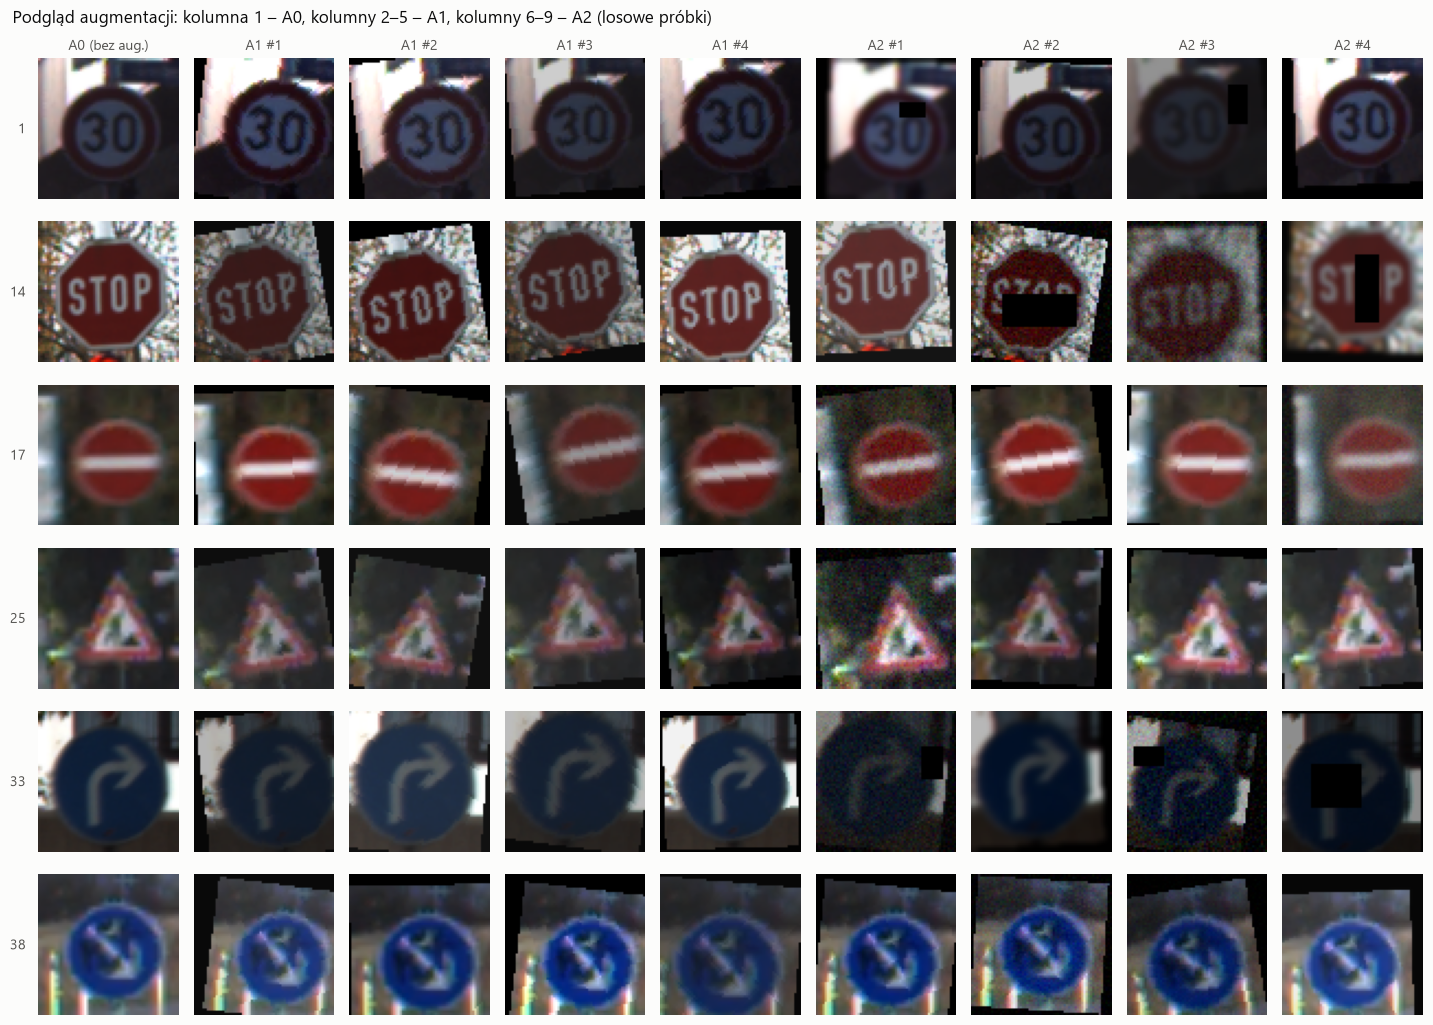

In [8]:
aug_classes = [1, 14, 17, 25, 33, 38]
paths = [full[full.ClassId == c].sample(1, random_state=SEED).Path.iloc[0] for c in aug_classes]
columns = [("A0", 1), ("A1", 4), ("A2", 4)]
tfs = {aug: build_transform(aug) for aug, _ in columns}

seed_everything(SEED)
n_cols = sum(n for _, n in columns)
fig, axes = plt.subplots(len(paths), n_cols, figsize=(1.6 * n_cols, 1.75 * len(paths)))
for r, (cls, path) in enumerate(zip(aug_classes, paths)):
    img = load_rgb(path)
    c = 0
    for aug, n in columns:
        for k in range(n):
            title = None
            if r == 0:
                title = "A0 (bez aug.)" if aug == "A0" else f"{aug} #{k + 1}"
            show(axes[r, c], to_display(tfs[aug](img)), title, fontsize=10)
            c += 1
    axes[r, 0].text(-6, 32, str(cls), ha="right", va="center", fontsize=10, color=INK2)
fig.suptitle("Podgląd augmentacji: kolumna 1 – A0, kolumny 2–5 – A1, kolumny 6–9 – A2 (losowe próbki)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
save(fig, "augmentation_preview.png")

## 8. Podsumowanie liczbowe

Zapis do `results/eda/summary.json`.

In [9]:
tracks_per_class = full.groupby("ClassId").track.nunique()
summary = {
    "dataset": "GTSRB (Kaggle), data/Train + data/Test",
    "n_classes": NUM_CLASSES,
    "input_size_px": IMG_SIZE,
    "train_folder": {
        "images": len(full),
        "tracks": int(full.track.nunique()),
        "frames_per_track": {"min": int(frames.min()), "median": int(frames.median()), "max": int(frames.max())},
        "images_per_class": {"min": int(per_class.min()), "min_class": int(per_class.idxmin()),
                             "max": int(per_class.max()), "max_class": int(per_class.idxmax())},
        "tracks_per_class": {"min": int(tracks_per_class.min()), "max": int(tracks_per_class.max())},
        "imbalance_ratio_max_min": round(float(per_class.max() / per_class.min()), 2),
    },
    "split": {
        "file": "splits/val_tracks.json",
        "method": "StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42), groups = track",
        **split,
        "max_class_share_diff_train_val_pp": round(float(max_share_diff), 3),
    },
    "test": {
        "images": len(test_df),
        "images_per_class": {"min": int(counts.test.min()), "max": int(counts.test.max())},
    },
    "image_size_px": sizes,
    "brightness_train_folder": {
        "scale": "mean luminance 0-255",
        "p1": float(q[0.01]), "p5": float(q[0.05]), "median": float(q[0.5]), "p95": float(q[0.95]),
        "share_below_30": round(float((b < 30).mean()), 4),
        "share_below_50": round(float((b < 50).mean()), 4),
    },
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "dataset": "GTSRB (Kaggle), data/Train + data/Test",
  "n_classes": 43,
  "input_size_px": 64,
  "train_folder": {
    "images": 39209,
    "tracks": 1307,
    "frames_per_track": {
      "min": 29,
      "median": 30,
      "max": 30
    },
    "images_per_class": {
      "min": 210,
      "min_class": 0,
      "max": 2250,
      "max_class": 2
    },
    "tracks_per_class": {
      "min": 7,
      "max": 75
    },
    "imbalance_ratio_max_min": 10.71
  },
  "split": {
    "file": "splits/val_tracks.json",
    "method": "StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42), groups = track",
    "n_images": {
      "train": 31349,
      "val": 7860
    },
    "n_tracks": {
      "train": 1045,
      "val": 262
    },
    "val_fraction_tracks": 0.2005,
    "val_fraction_images": 0.2005,
    "shared_tracks": 0,
    "val_classes": 43,
    "val_min_images_per_class": 30,
    "val_min_images_class": 0,
    "val_min_tracks_per_class": 1,
    "max_class_share_diff_train_val_pp"

## Wnioski

1. **Nierównowaga klas ok. 10,7×** (klasa 0: 210 zdjęć, klasa 2: 2 250). Test ma taki sam kształt rozkładu, a walidacja
   odwzorowuje train z dokładnością do 0,4 p.p. udziału klasy. Obok accuracy raportujemy więc **macro-F1** i na nim robimy early stopping.
2. **Podział po seriach działa:** 262 z 1 307 serii (20,1%) w walidacji, 0 wspólnych serii, wszystkie 43 klasy obecne.
   Klasy 0, 19, 29, 32 i 37 mają w walidacji tylko 1 serię (30 zdjęć), więc ich F1 walidacyjne opiera się na jednym fizycznym
   znaku i trzeba je czytać ostrożnie.
3. **Zdjęcia są małe:** mediana 43 px, ok. 79% zdjęć ma oba boki < 64 px, więc wejście 64×64 to dla większości powiększenie.
   Proporcje są bliskie 1:1 (W/H od 0,81 do 1,17 dla 98% zdjęć Train/), więc skalowanie do kwadratu bez paddingu
   prawie nie zniekształca znaków. Rozkłady rozmiarów Train/ i Test/ niemal się pokrywają.
4. **Serie to ok. 30 kolejnych klatek tego samego znaku**, który rośnie w miarę zbliżania się samochodu (np. 32 → 88 px).
   To bliskie duplikaty, stąd podział po seriach. Ramki ROI po przeskalowaniu do 64×64 pokrywają znak (kontrola do XAI w KM3).
5. **Dużo zdjęć jest naturalnie ciemnych:** mediana jasności 74/255, 5% zdjęć ma jasność < 20, a 14% < 30. Najciemniejsze serie
   pochodzą z różnych klas. Zakłócenie `darken` w KM2 trzeba skalibrować względem tego zakresu, bo słabe przyciemnienie
   nie wyjdzie poza to, co model już widział w treningu.
6. **Augmentacje:** A1 zachowuje kierunek znaków (33, 38). Pierwsza wersja A2 (przyciemnienie ×0.3–0.8, szum σ do 0.08)
   na i tak ciemnych zdjęciach potrafiła prawie wymazać znak, więc przed treningiem osłabiliśmy oba zakresy (sekcja 7).
   Po zmianie te same próbki (STOP w kolumnie A2 #3, strzałka klasy 33 w A2 #1 i #3) są trudne, ale znak da się odczytać.
   Jeśli A2 mimo to wyraźnie obniży accuracy na czystych danych, wracamy do tych parametrów.